# Sales Trend and Customer Analysis

## Business questions
A manager wants to know:
1. Which months earn the most revenue, and how is revenue growing?
2. Which product categories earn the most?
3. Who are our best customers, and how much revenue do the top 10% bring?
4. What should we do next?

## Data note
The data is **generated** (simulated), not real customer data. It is a made-up order table for 2025, with amounts assumed to be in rupees (INR). All findings describe this simulated data only.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(42)   # fixed seed, so we get the same data every run
n = 2000                          # number of orders

orders = pd.DataFrame({
    "order_id": np.arange(1, n + 1),
    "order_date": pd.to_datetime("2025-01-01") + pd.to_timedelta(rng.integers(0, 365, n), unit="D"),
    "customer_id": rng.integers(1, 301, n),
    "category": rng.choice(["Electronics", "Fashion", "Home", "Books"], n, p=[0.30, 0.35, 0.20, 0.15]),
    "amount": rng.gamma(2.0, 600, n).round(2),
})

print("Rows and columns:", orders.shape)
orders.head()

Rows and columns: (2000, 5)


,order_id,order_date,customer_id,category,amount
0,1,2025-02-02,264,Home,391.13
1,2,2025-10-10,19,Fashion,2456.21
2,3,2025-08-27,120,Books,674.90
3,4,2025-06-10,138,Home,75.38
4,5,2025-06-08,240,Electronics,774.42


In [2]:
orders.info()
print()
print("Missing values:", orders.isna().sum().sum())
print("Duplicate rows:", orders.duplicated().sum())
orders.describe()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   order_id     2000 non-null   int64         
 1   order_date   2000 non-null   datetime64[us]
 2   customer_id  2000 non-null   int64         
 3   category     2000 non-null   str           
 4   amount       2000 non-null   float64       
dtypes: datetime64[us](1), float64(1), int64(2), str(1)
memory usage: 92.7 KB

Missing values: 0
Duplicate rows: 0


,order_id,order_date,customer_id,amount
count,2000.000000,2000,2000.000000,2000.000000
mean,1000.500000,2025-07-01 22:45:07.200000,151.195500,1202.116645
min,1.000000,2025-01-01 00:00:00,1.000000,8.810000
25%,500.750000,2025-03-31 18:00:00,74.000000,597.515000
50%,1000.500000,2025-07-02 00:00:00,149.000000,1005.870000
75%,1500.250000,2025-10-03 00:00:00,226.000000,1613.855000
max,2000.000000,2025-12-31 00:00:00,300.000000,6276.090000
std,577.494589,NaN,86.210007,826.961568


## Date features

In [3]:
orders["month"] = orders["order_date"].dt.to_period("M")
orders["weekday"] = orders["order_date"].dt.day_name()
orders["quarter"] = orders["order_date"].dt.quarter

orders[["order_date", "month", "weekday", "quarter"]].head()

,order_date,month,weekday,quarter
0,2025-02-02,2025-02,Sunday,1
1,2025-10-10,2025-10,Friday,4
2,2025-08-27,2025-08,Wednesday,3
3,2025-06-10,2025-06,Tuesday,2
4,2025-06-08,2025-06,Sunday,2


## Monthly revenue trend

In [4]:
monthly = orders.groupby("month")["amount"].sum().round(0)

summary = pd.DataFrame({
    "revenue": monthly,
    "growth_%": (monthly.pct_change() * 100).round(1)
})
print(summary)
print()
print("Best month:", monthly.idxmax(), "| Worst month:", monthly.idxmin())

          revenue  growth_%
month                      
2025-01  193342.0       NaN
2025-02  232027.0      20.0
2025-03  206327.0     -11.1
2025-04  197310.0      -4.4
2025-05  194090.0      -1.6
2025-06  221890.0      14.3
2025-07  221814.0      -0.0
2025-08  179784.0     -18.9
2025-09  180570.0       0.4
2025-10  183418.0       1.6
2025-11  191513.0       4.4
2025-12  202148.0       5.6

Best month: 2025-02 | Worst month: 2025-08


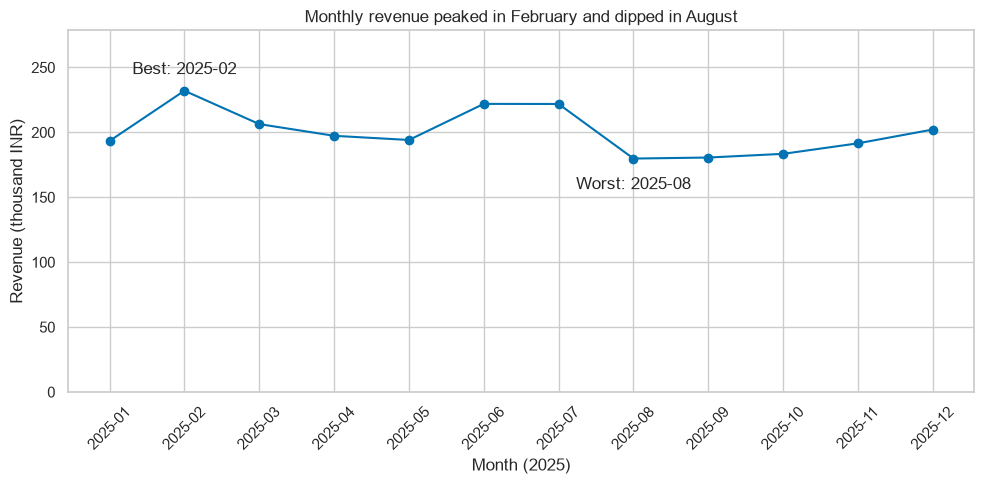

In [5]:
sns.set_theme(style="whitegrid", palette="colorblind")

best, worst = monthly.idxmax(), monthly.idxmin()
months = monthly.index.astype(str)
revenue_k = monthly.values / 1000          # show in thousands so the axis is readable

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(months, revenue_k, marker="o")

ax.annotate(f"Best: {best}", xy=(str(best), monthly[best] / 1000),
            xytext=(0, 12), textcoords="offset points", ha="center")
ax.annotate(f"Worst: {worst}", xy=(str(worst), monthly[worst] / 1000),
            xytext=(0, -22), textcoords="offset points", ha="center")

ax.set_ylim(0, revenue_k.max() * 1.2)      # start at zero so swings are not exaggerated
ax.set(title="Monthly revenue peaked in February and dipped in August",
       xlabel="Month (2025)", ylabel="Revenue (thousand INR)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Takeaway:** Monthly revenue stayed between about 180,000 and 232,000 INR. February was the best month (232,027 INR, up 20% from January) and August the worst (179,784 INR, down 18.9% from July). Because the data is simulated, these swings reflect chance rather than real seasonality.

## Comparing categories

In [6]:
by_category = (orders.groupby("category")["amount"]
               .agg(total="sum", average="mean", orders="count")
               .sort_values("total", ascending=False)
               .round(0))

by_category["share_%"] = (by_category["total"] / by_category["total"].sum() * 100).round(1)
print(by_category)

                total  average  orders  share_%
category                                       
Fashion      853985.0   1220.0     700     35.5
Electronics  722646.0   1164.0     621     30.1
Home         464115.0   1218.0     381     19.3
Books        363488.0   1220.0     298     15.1


In [7]:
pivot = orders.pivot_table(index="month", columns="category",
                           values="amount", aggfunc="sum").round(0)
pivot

category,Books,Electronics,Fashion,Home
month,,,,
2025-01,29187.0,62842.0,64666.0,36647.0
2025-02,34034.0,53565.0,86123.0,58305.0
2025-03,27844.0,58056.0,75139.0,45289.0
2025-04,26594.0,83336.0,57058.0,30323.0
2025-05,34426.0,57219.0,68570.0,33876.0
2025-06,32937.0,60037.0,85598.0,43318.0
2025-07,35582.0,72650.0,72648.0,40934.0
2025-08,32551.0,56690.0,71252.0,19291.0
2025-09,21825.0,60389.0,60232.0,38125.0


**Takeaway:** Fashion is the top category, earning about 853,985 INR (35.5% of revenue), followed by Electronics (30.1%), Home (19.3%) and Books (15.1%). Average order value is similar across categories (about 1,164 to 1,220 INR), so the ranking is driven by the number of orders, not order size. Fashion leads in 9 of 12 months. The weakest month-category result is Home in August (19,291 INR).

## Best customers

In [8]:
spend = orders.groupby("customer_id")["amount"].sum().sort_values(ascending=False)

print("Number of customers:", len(spend))
print("Average orders per customer:", round(len(orders) / len(spend), 1))
print()

for pct in (0.10, 0.20):
    k = int(len(spend) * pct)
    share = spend.head(k).sum() / spend.sum()
    print(f"Top {pct:.0%} ({k} customers) bring {share:.1%} of revenue")

print()
print("Top 5 customers by total spend:")
print(spend.head(5).round(0))

Number of customers: 300
Average orders per customer: 6.7

Top 10% (30 customers) bring 18.9% of revenue
Top 20% (60 customers) bring 33.9% of revenue

Top 5 customers by total spend:
customer_id
226    18140.0
51     18126.0
53     17994.0
131    17639.0
185    17222.0
Name: amount, dtype: float64


**Takeaway:** The 80/20 idea does not hold here. The top 10% of customers (30 of 300) bring only 18.9% of revenue, and the top 20% bring 33.9%. The biggest single customer accounts for less than 1% of revenue. Revenue is spread widely across customers, so no small group carries the business.

## Recommendations
1. **Run a broad loyalty offer, not a VIP-only one.** The top 10% of customers bring only 18.9% of revenue, so a top-customer programme would reach a small slice. With 6.7 orders per customer on average, a repeat-purchase offer open to all 300 customers is a better target.
2. **Focus stock and marketing on Fashion and Electronics.** Together they bring 65.6% of revenue (35.5% + 30.1%). Average order value is similar across categories (about 1,164 to 1,220 INR), so growing Books (298 orders) and Home (381 orders) means getting more orders, for example through bundles with the top two categories.
3. **Plan a promotion for the slow late-summer period.** August was the weakest month (179,784 INR, down 18.9% from July), and Home was especially low that month (19,291 INR). A targeted August offer could lift this dip. Because the data is simulated, this should be checked against real multi-year sales before acting.